In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Reading Transformed Stock Data for Portfolio

In [7]:
# Reading Log Returns for Each Asset and the Interest Rates for the Credit

# STOCK DATA
portfolio_df = pd.read_csv("_portfolio_returns.csv", index_col=["Date"]).drop(columns=["EUR_USD"])
# portfolio_df = portfolio_df.drop(columns=["EUR_USD"]) # For now just drop, need answer to Q1
# portfolio_df = portfolio_df*(-1)      # Converting into Loss Distribution. instead of P/L, IT IS THAT SIMPLE RIGHT?

# Reading Rates for Credit
euribor = pd.read_csv("_EURIBOR_monthly_rates.csv", index_col=["Date"])
# ...       # Nothing for now, need answer to Q2

# Declaring weights for portfolio construction, DON'T FORGET TO UPDAtE ONCE CREDIT IS ADDED
PORTFOLIO_WEIGHTS= np.array([0.15, 0.2, 0.15, 0.15, 0.15, 0.2])     # If we short something we can get more cash to invest

## QUESTIONS: 
### SHOULD WE JUST CONVERT EACH DAY TO EURO RETURNS? ARE WE EXPOSED EVERY DAY? THAT IS THE POINT RIGHT? OR ONLY ON BUY/SELL DAYS AND COMPARE?
### I HAVE NO IDEA HOW TO CALCULATE RETURNS/LOSES ON CREDIT. HOW IS IT DONE GIVEN RATES?
### JUST MULTIPLY BY -1 TO GET LOSS DISTRIBUTION. IT IS JUST FOR THE CONVENTION RIGHT? NO REAL DIFFERENCE?
### QQPLOT MUST HAVE A LINE=Q, WHICH GOES THROUGH QUANTILES, NOT JUST 45 DEGREEES? IT DOES NOT MAKE MUCH SENSE, AS IT IS OBVIOUSLY IS NOT STANDARD NORMAL DISTRIBUTION, CORRECT?
### DO WE CALCULATE RETURNS PROPERLY? WE USE LOG RETURNS.
### SHOULD WE JUST DROP ZEROS FROM NON-TRADING DAYS FOR THE VISUALIZATION?

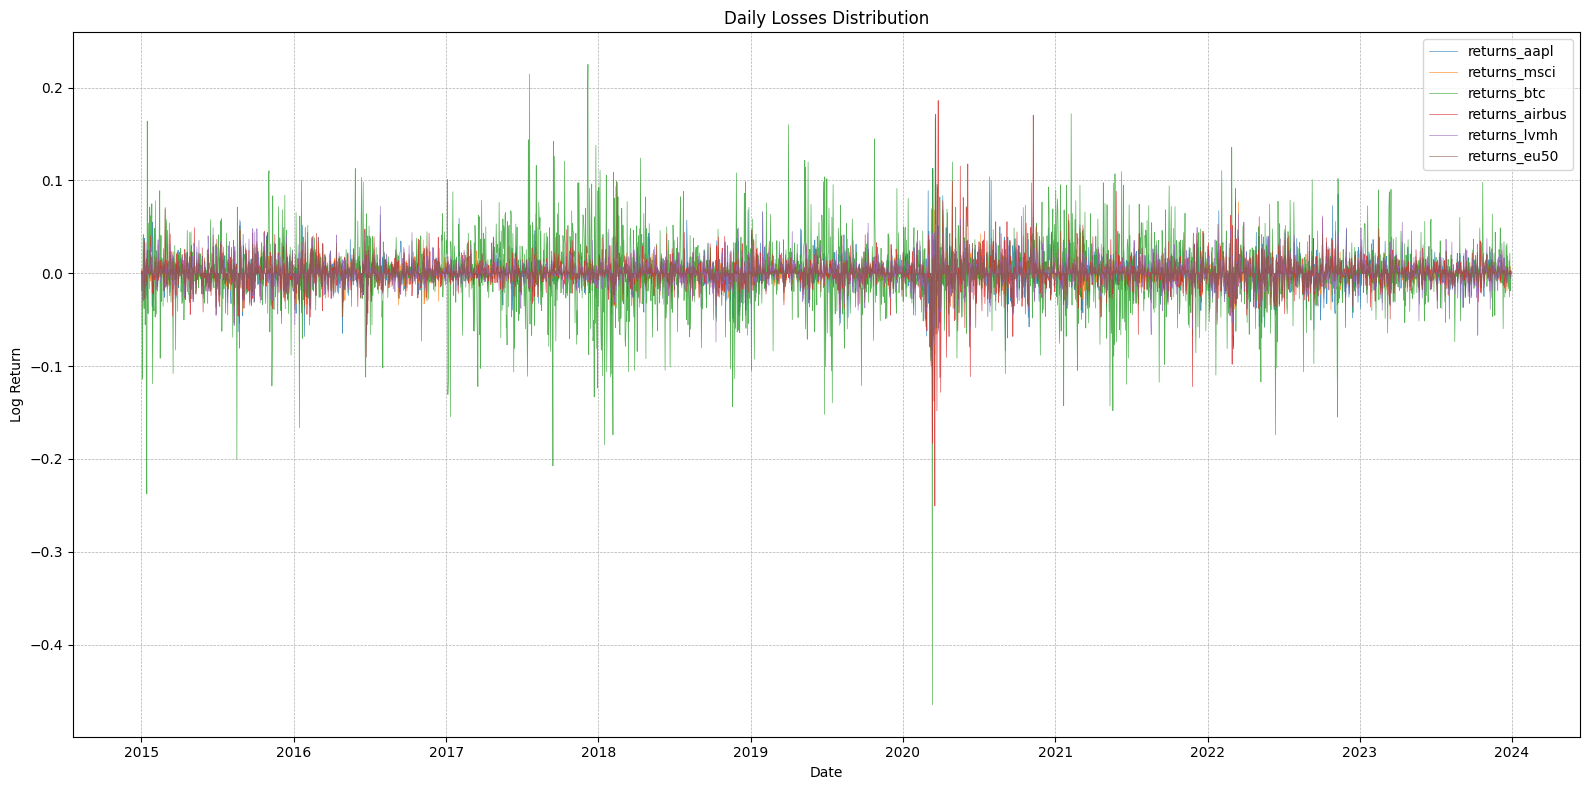

In [9]:
# Plotting
plt.figure(figsize=(16, 8))
portfolio_df.index = pd.to_datetime(portfolio_df.index)       # Making sure matplotlib recognizes the datetime index

for column in portfolio_df.columns:
    plt.plot(portfolio_df.index, portfolio_df[column], lw=.5, alpha=0.8, label=column)

# Setting the x-axis to only show years
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.legend()
plt.title('Daily Losses Distribution')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True, linestyle='--', linewidth=0.5)
plt.tight_layout()

plt.show()


# Value-at-Risk and Expected Shortfall with Variance-CoVariance method

### Functions that are necessary for all methods

In [13]:
window_size = 250
data = portfolio_df

rolling_vol: pd.DataFrame = data.rolling(window = window_size).std(ddof = 0).dropna()

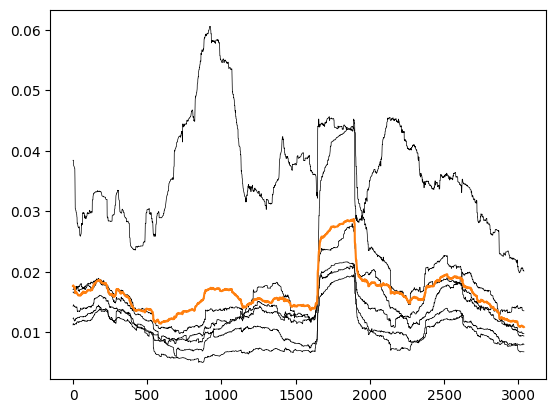

In [24]:
plt.plot(rolling_vol.values, color = "black", lw = .5)
plt.plot(rolling_vol.values @ PORTFOLIO_WEIGHTS, color = "C1")

In [43]:
from typing import Callable, Any

def PortRet(*, data: pd.DataFrame, weights: np.array) -> pd.DataFrame:
    return data @ weights

def VCV(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the Value at Risk metric using dist
    """
    rolling_vol: pd.DataFrame = data.rolling(window = window_size).std(ddof = 0).dropna()
    portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights

    portfolio_VaR = pd.DataFrame(portfolio_volatility, index = rolling_vol.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = portfolio_volatility * dist(alpha, **kwargs)
    return portfolio_VaR

In [50]:
VaR_data_norm = VCV(portfolio_df, window_size = 250, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.norm.ppf)
VaR_data_t_df4 = VCV(portfolio_df, window_size = 250, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 4)
VaR_data_t_df5 = VCV(portfolio_df, window_size = 250, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 5)
VaR_data_t_df6 = VCV(portfolio_df, window_size = 250, port_weights = PORTFOLIO_WEIGHTS, alpha = .05, dist = stats.t.ppf, df = 6)

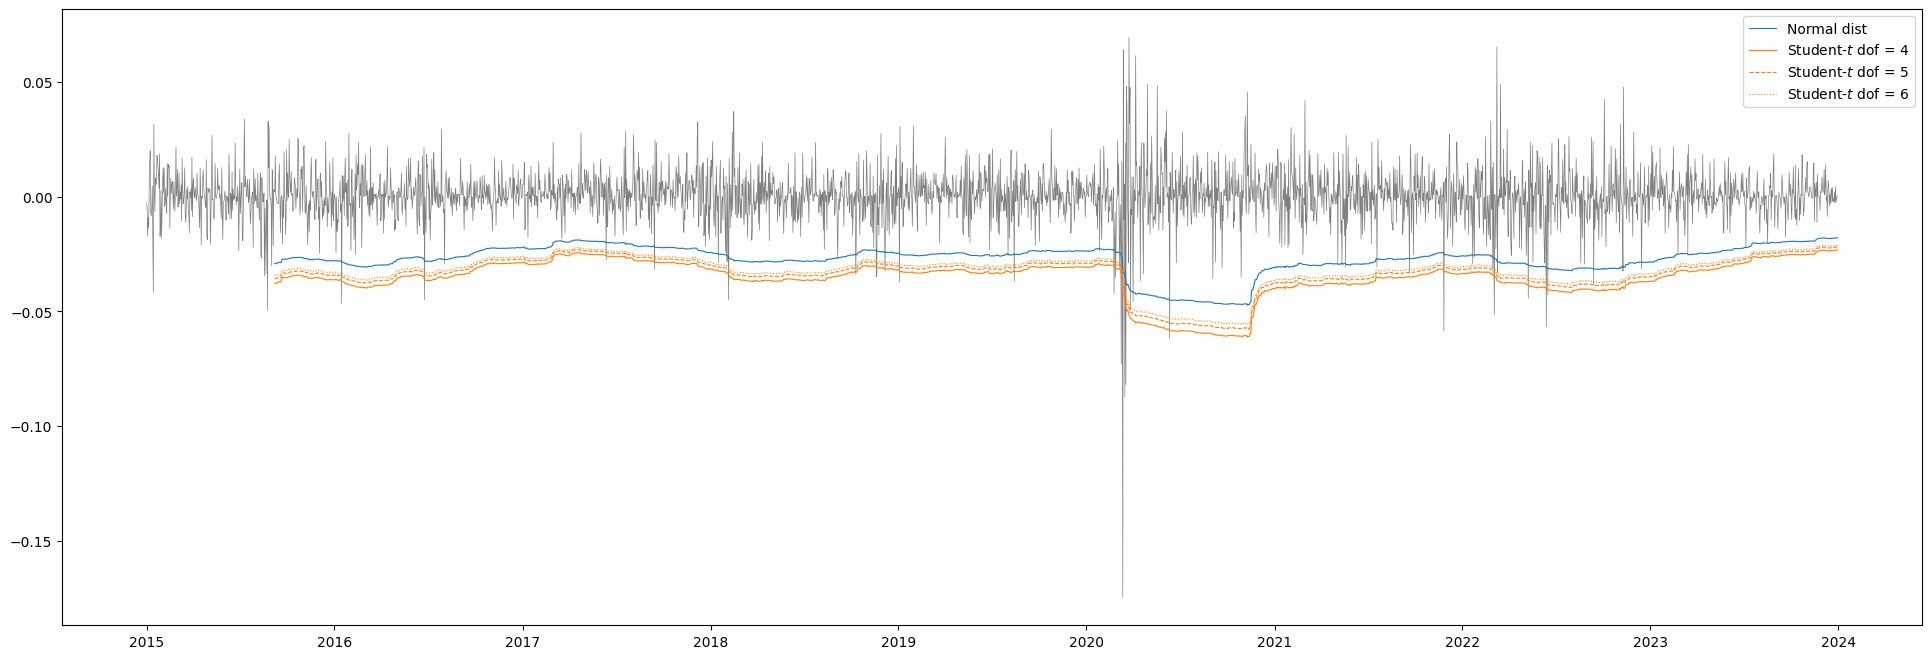

In [54]:
plt.rcParams['figure.figsize'] = (24, 8)
plt.plot(PortRet(data = portfolio_df, weights = PORTFOLIO_WEIGHTS), lw = .5, c = 'black', alpha = .5)
plt.plot(VaR_data_norm.VaR, label = 'Normal dist', lw = .8)
plt.plot(VaR_data_t_df4.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
plt.plot(VaR_data_t_df5.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
plt.plot(VaR_data_t_df6.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
plt.legend()
plt.show()

In [351]:
def calculate_var_normal(annual_volatility, mean_return, z_score):
    """
    Calculate the Value at Risk (VaR) using the Normal distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - z_score (float): The Z-score corresponding to the desired confidence level.

    Returns:
    - float: The calculated VaR.
    """
    return mean_return + z_score * annual_volatility

def calculate_var_student_t(annual_volatility, mean_return, t_critical_value, degrees_of_freedom):
    """
    Calculate the Value at Risk (VaR) using Student's T-distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - t_critical_value (float): The critical value from the T-distribution corresponding to the desired confidence level.
    - degrees_of_freedom (int): The degrees of freedom for the T-distribution.

    Returns:
    - float: The calculated VaR adjusted for the fat tails of the T-distribution.
    """
    adjusted_volatility = annual_volatility / np.sqrt(degrees_of_freedom / (degrees_of_freedom - 2))
    return mean_return + t_critical_value * adjusted_volatility

def calculate_es_normal(annual_volatility, mean_return, z_score, confidence_level):
    """
    Calculate the Expected Shortfall (ES) using the Normal distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - z_score (float): The Z-score corresponding to the desired confidence level.
    - confidence_level (float): The confidence level as a decimal (e.g., 0.95 for 95%).

    Returns:
    - float: The calculated ES.
    """
    density_at_z = stats.norm.pdf(z_score)
    return (density_at_z / (1 - confidence_level)) * annual_volatility + mean_return

def calculate_es_student_t(annual_volatility, mean_return, t_critical_value, degrees_of_freedom, confidence_level):
    """
    Calculate the Expected Shortfall (ES) using Student's T-distribution method.

    Parameters:
    - annual_volatility (float): The annual volatility of the portfolio or asset.
    - mean_return (float): The mean return of the portfolio or asset.
    - t_critical_value (float): The critical value from the T-distribution corresponding to the desired confidence level.
    - degrees_of_freedom (int): The degrees of freedom for the T-distribution.
    - confidence_level (float): The confidence level as a decimal (e.g., 0.95 for 95%).

    Returns:
    - float: The calculated ES adjusted for the fat tails of the T-distribution.
    """
    adjusted_volatility = annual_volatility / np.sqrt(degrees_of_freedom / (degrees_of_freedom - 2))
    density_at_t = stats.t.pdf(t_critical_value, degrees_of_freedom)
    return (density_at_t / (1 - confidence_level)) * ((degrees_of_freedom + t_critical_value**2) / (degrees_of_freedom - 1)) * adjusted_volatility + mean_return

def calculate_portfolio_risk_metrics(weight_vector, log_losses, distribution_method="Normal", degrees_of_freedom=1):
    """
    Calculate Value at Risk (VaR) and Expected Shortfall (ES) for a portfolio using either
    Normal or Student's t-distribution methods.

    Parameters:
    - weight_vector (np.array): The weight of each asset in the portfolio.
    - log_losses (np.array): Logarithmic losses of the assets in the portfolio.
    - distribution_method (str): Specifies the distribution method to use for calculating VaR and ES. 
      Accepts "Normal" for Normal distribution or "Student" for Student's t-distribution.
    - degrees_of_freedom (int): The degrees of freedom for the Student's t-distribution. 
      This parameter is ignored if distribution_method is "Normal".

    Returns:
    - tuple: A tuple containing the calculated VaR and ES values at 97.5% and 99% confidence levels (Four Floats Overall: VaR_975, VaR_99, ES_975, ES_99).
    """

    # Estimate Variance-Covariance matrix of portfolio returns
    covariance_matrix = np.cov(log_losses, rowvar=False)

    # Calculate portfolio volatility
    portfolio_volatility = np.sqrt(weight_vector.T @ covariance_matrix @ weight_vector)
    # Assuming mean return (mu) is zero for a short horizon
    mean_return = 0

    # Initialize variables for clarity
    VaR_975, VaR_99, ES_975, ES_99 = 0, 0, 0, 0

    # Calculate VaR and ES based on the specified distribution method
    if distribution_method == "Normal":
        # Z-scores for 97.5% and 99% confidence intervals for Normal distribution
        z_975, z_99 = 1.96, 2.33
        VaR_975 = calculate_var_normal(portfolio_volatility, mean_return, z_975)
        VaR_99 = calculate_var_normal(portfolio_volatility, mean_return, z_99)
        ES_975 = calculate_es_normal(portfolio_volatility, mean_return, z_975, 0.975)
        ES_99 = calculate_es_normal(portfolio_volatility, mean_return, z_99, 0.99)
    elif distribution_method == "Student":
        # Critical t-values for 97.5% and 99% confidence intervals for Student's t-distribution
        t_975 = stats.t.ppf(0.975, degrees_of_freedom)
        t_99 = stats.t.ppf(0.99, degrees_of_freedom)
        VaR_975 = calculate_var_student_t(portfolio_volatility, mean_return, t_975, degrees_of_freedom)
        VaR_99 = calculate_var_student_t(portfolio_volatility, mean_return, t_99, degrees_of_freedom)
        ES_975 = calculate_es_student_t(portfolio_volatility, mean_return, t_975, degrees_of_freedom, 0.975)
        ES_99 = calculate_es_student_t(portfolio_volatility, mean_return, t_99, degrees_of_freedom, 0.99)

    return VaR_975, VaR_99, ES_975, ES_99


## Normal Distribution Assumption

In [352]:
portfolio = portfolio_df.to_numpy()
portfolio_weighted = portfolio_df.dot(PORTFOLIO_WEIGHTS)

In [353]:
N = 6               # Number of Assets in the Portfolio
T = len(portfolio)  # Number of Observations

rolling_window = 250     # So that we can see how VaR/ES changes through time, with/without stress periods (COVID in 2020)
# Calculating VaR/ES
VarCovN_VaR_975 = np.zeros(T-rolling_window)
VarCovN_VaR_99 = np.zeros(T-rolling_window)
VarCovN_ES_975 = np.zeros(T-rolling_window)
VarCovN_ES_99 = np.zeros(T-rolling_window)
for i in range(T-rolling_window):
  (VarCovN_VaR_975[i], VarCovN_VaR_99[i], VarCovN_ES_975[i], VarCovN_ES_99[i]) = calculate_portfolio_risk_metrics(PORTFOLIO_WEIGHTS, portfolio[i:rolling_window+i,:], "Normal")

### Visualizing Normal Distribution Assumption per each Asset in the Portfolio

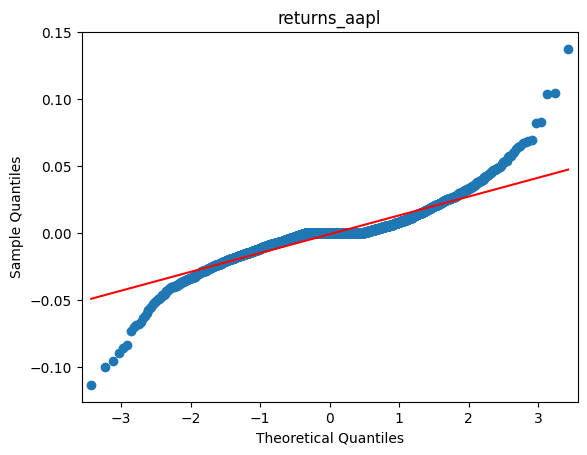

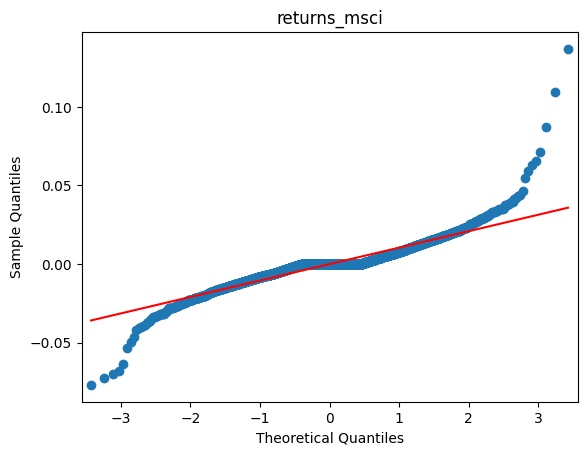

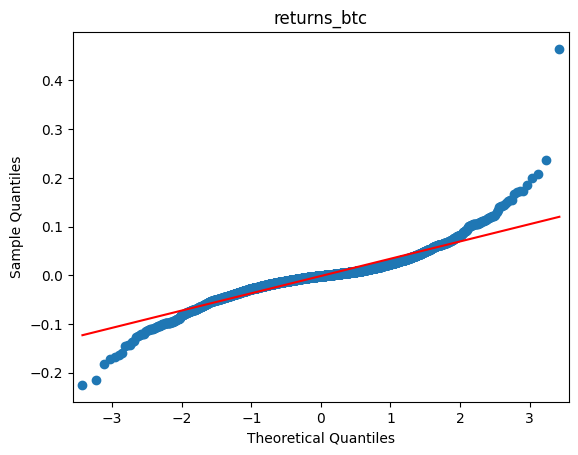

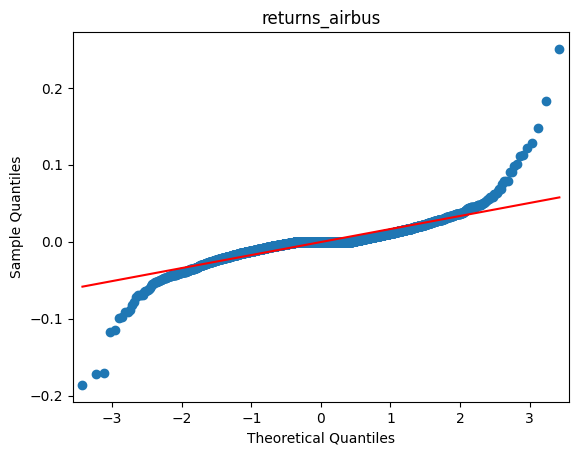

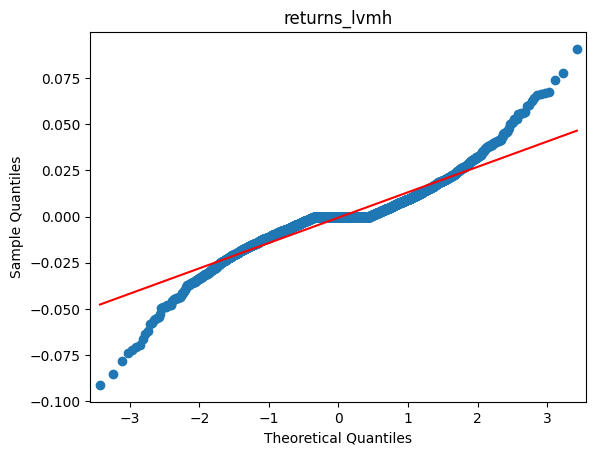

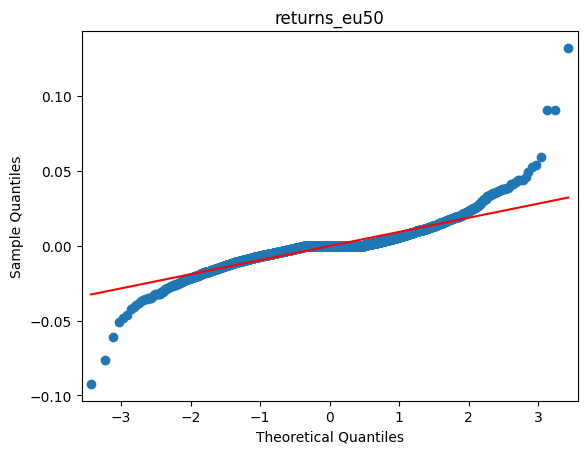

In [354]:
# QQ-Plot to see if asset returns follow normal distribution
for i in range(N):
    sm.qqplot(portfolio[:,i], line="r")     # IS LINE=Q OR LINE=R OR LINE 45? Q3
    plt.title(portfolio_df.columns[i])

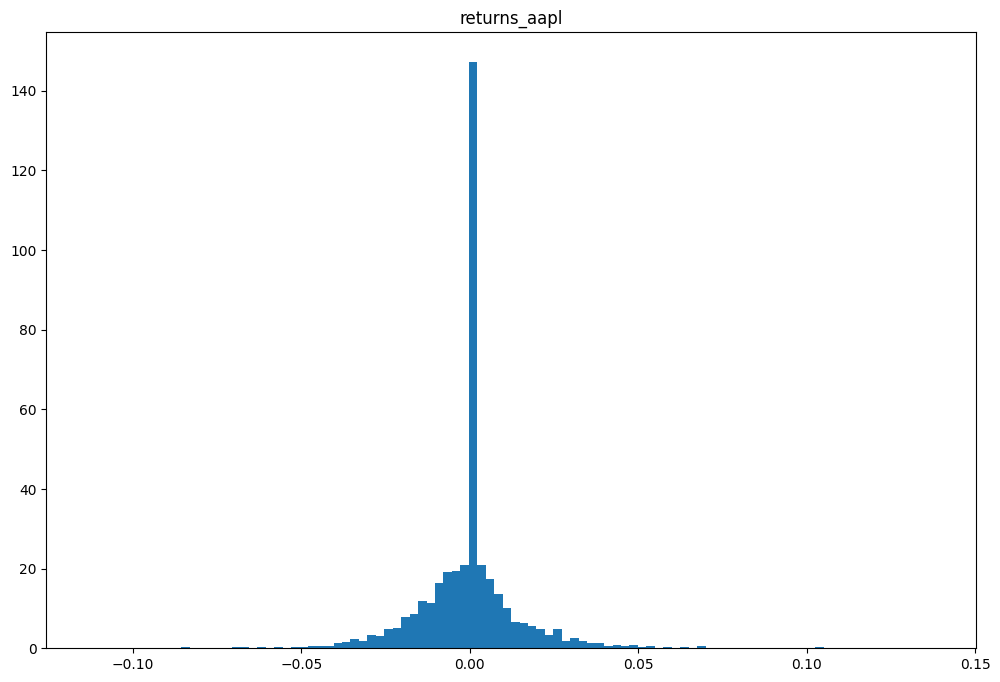

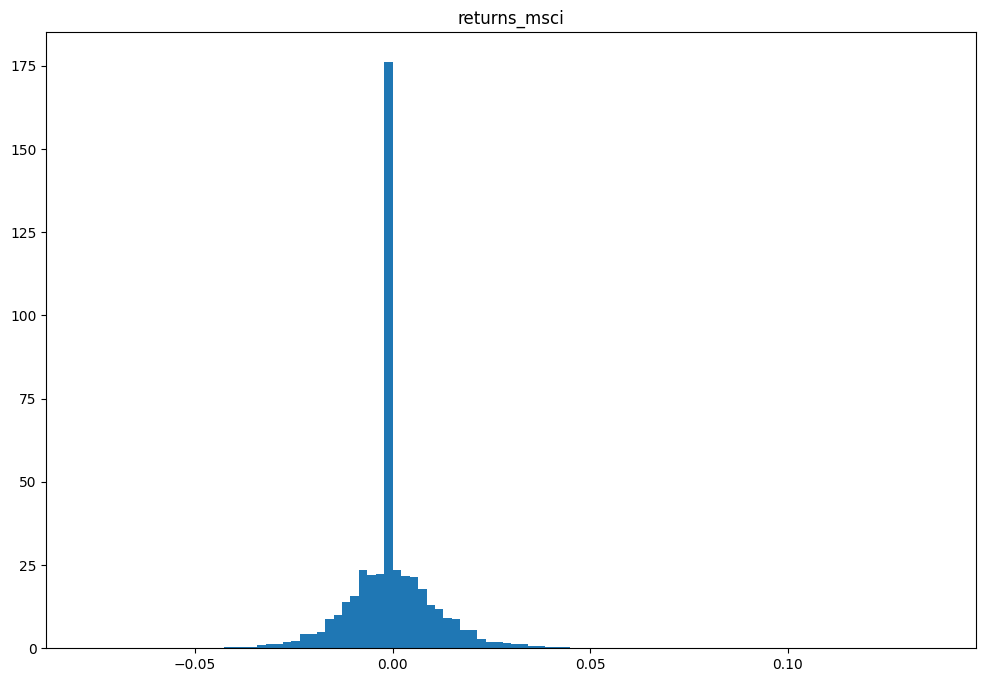

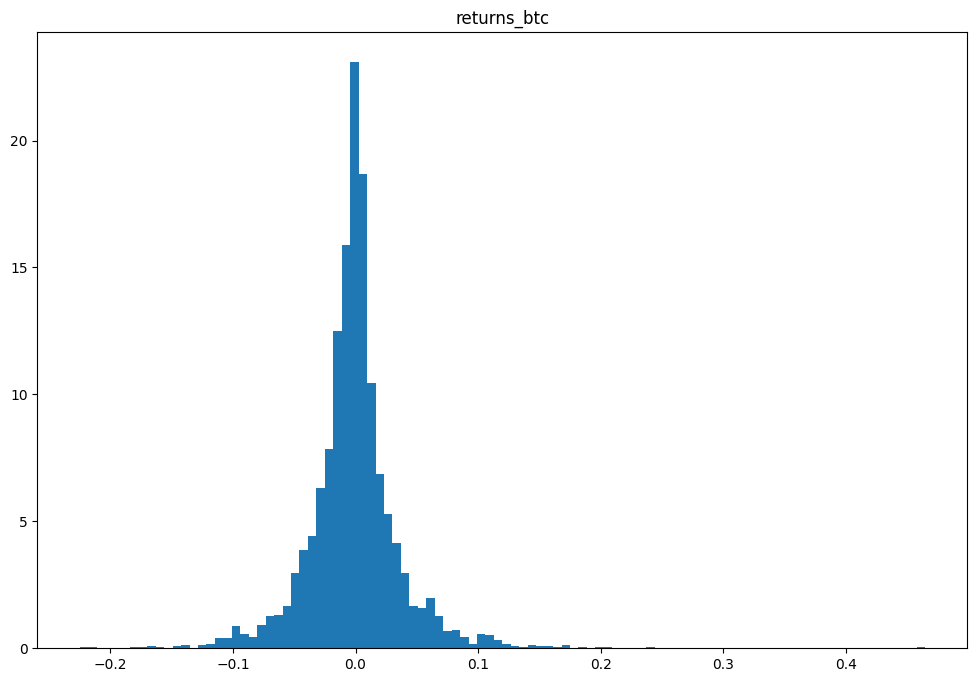

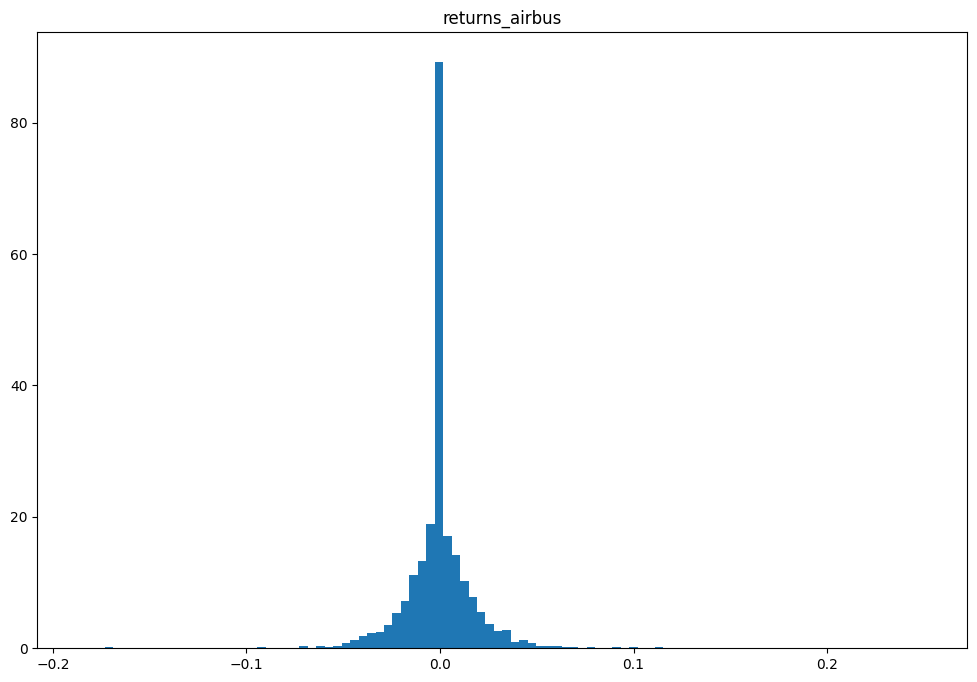

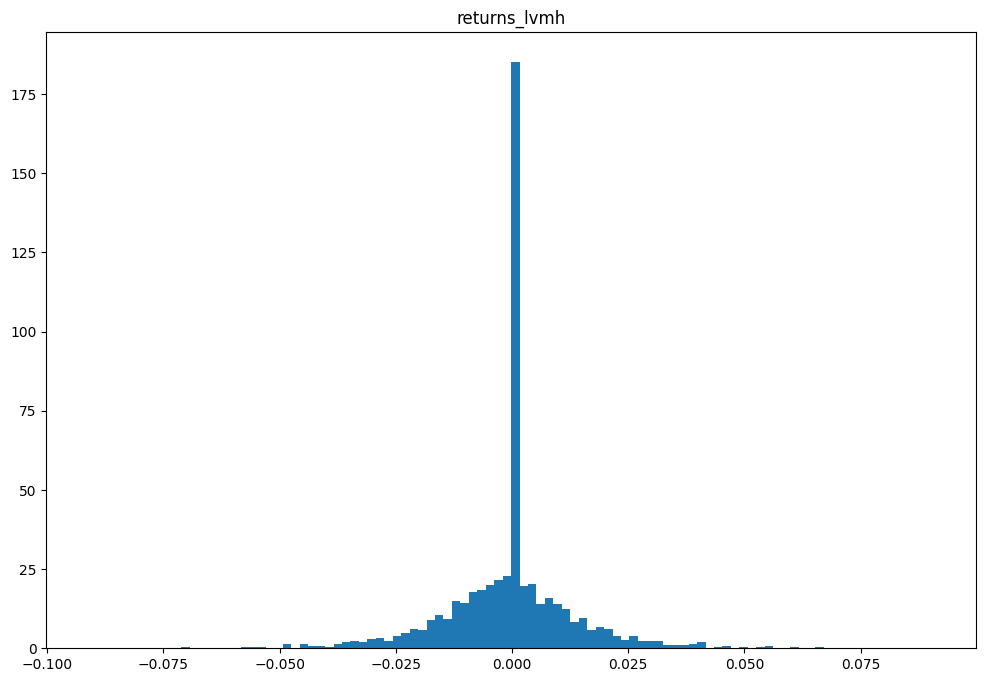

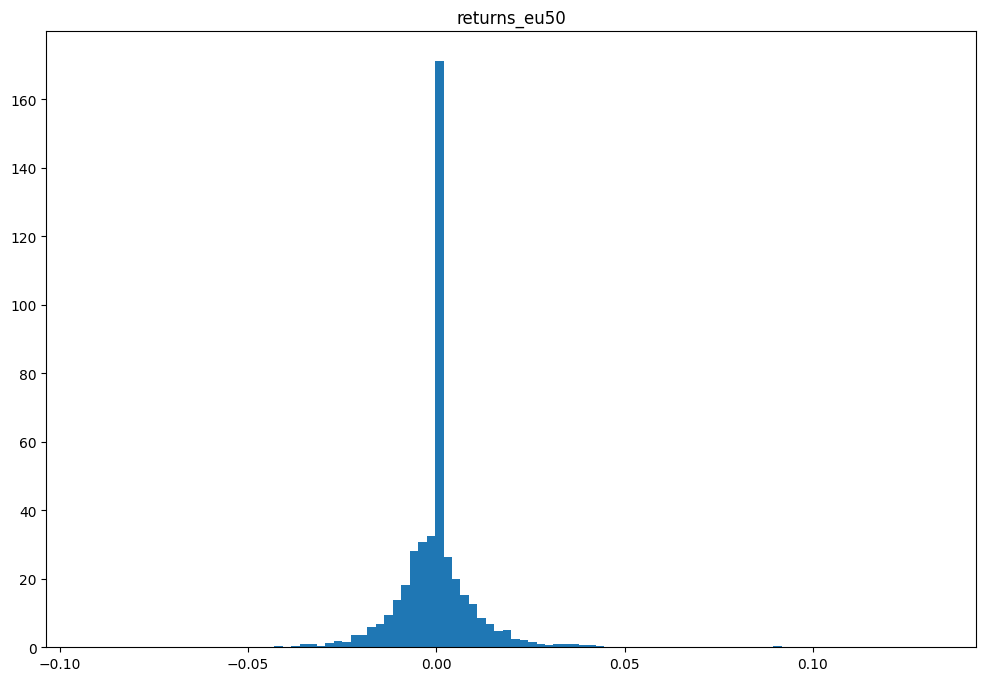

In [355]:
#Histogram of Asset Losses to see the Distribution outline
for i in range(N):
    plt.figure(figsize=(12, 8))
    plt.title(portfolio_df.columns[i])
    plt.hist(portfolio[:,i], bins=100, density=True)
    plt.show()

# SHOULD CORRECT FOR ZEROS GIVEN BY NON-TRADING DAYS
# PROBABLY USELESS PLOT ANYWAY

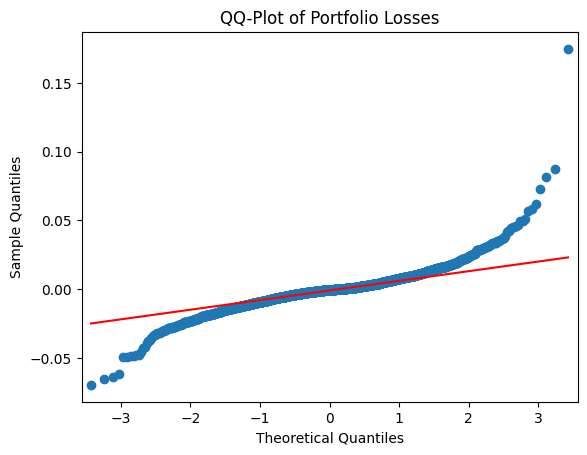

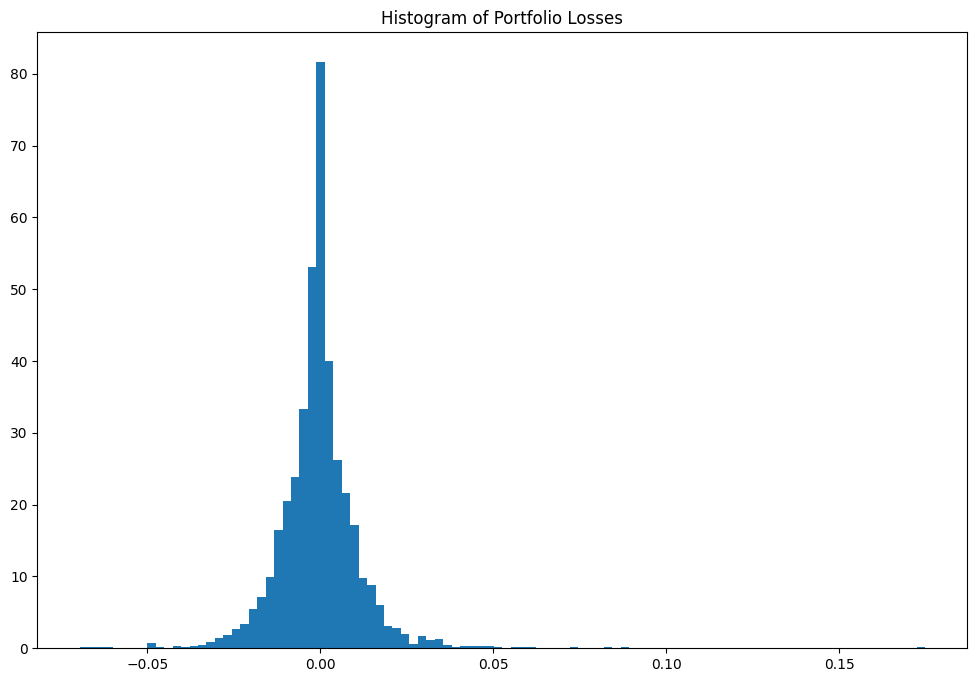

In [356]:
# Same but on Portfolio Level

#QQ-plot
sm.qqplot(portfolio_weighted, line='q')
plt.title("QQ-Plot of Portfolio Losses")

#Histogram
plt.figure(figsize=(12, 8))
plt.hist(portfolio_weighted, bins=100, density=True)
plt.title("Histogram of Portfolio Losses")
plt.show()

## t-Student Distribution Assumption

In [357]:
##Perform Student-t Var-Cov method
degrees_of_freedom = np.array([3, 4, 5, 6])
VarCovT_VaR_975= np.zeros((T-rolling_window, len(degrees_of_freedom)))
VarCovT_VaR_99= np.zeros((T-rolling_window, len(degrees_of_freedom)))
VarCovT_ES_975= np.zeros((T-rolling_window, len(degrees_of_freedom)))
VarCovT_ES_99= np.zeros((T-rolling_window, len(degrees_of_freedom)))
for i in range(T-rolling_window):
  (VarCovT_VaR_975[i,:], VarCovT_VaR_99[i,:], VarCovT_ES_975[i,:], VarCovT_ES_99[i,:])= calculate_portfolio_risk_metrics(PORTFOLIO_WEIGHTS, portfolio[i:rolling_window+i,:], "Student", degrees_of_freedom)

### Visualizing t-Student Distribution Assumption per each Asset in the Portfolio

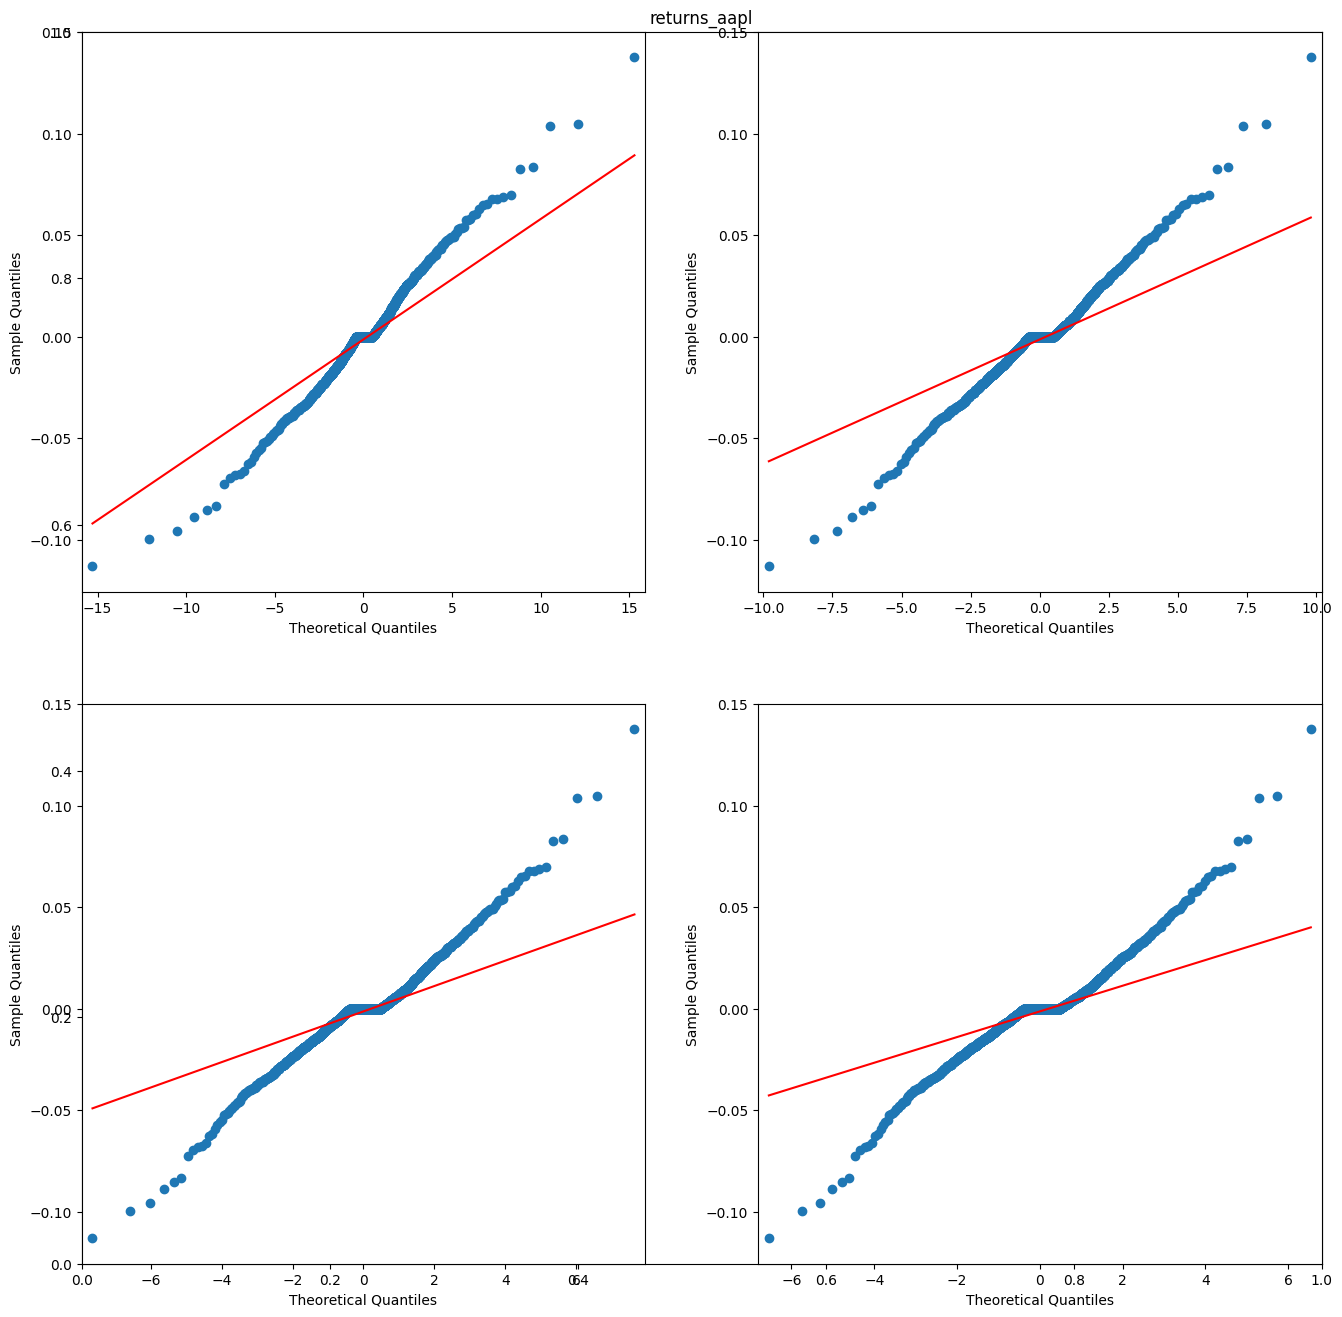

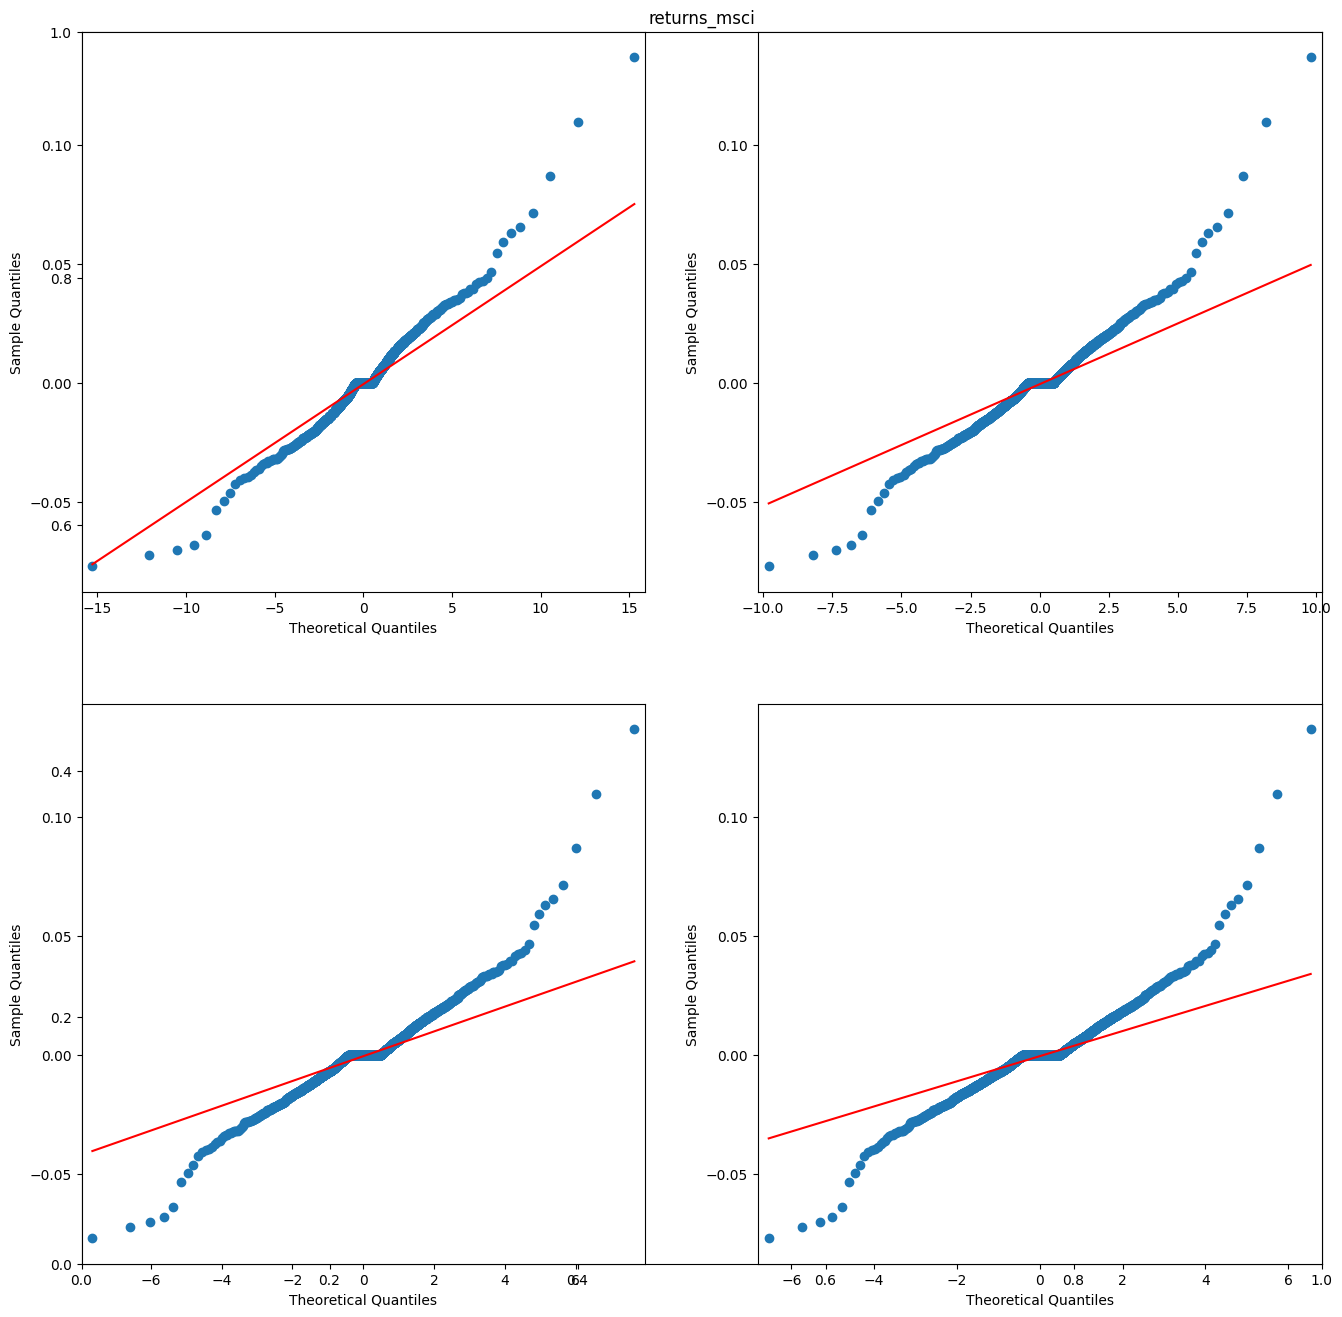

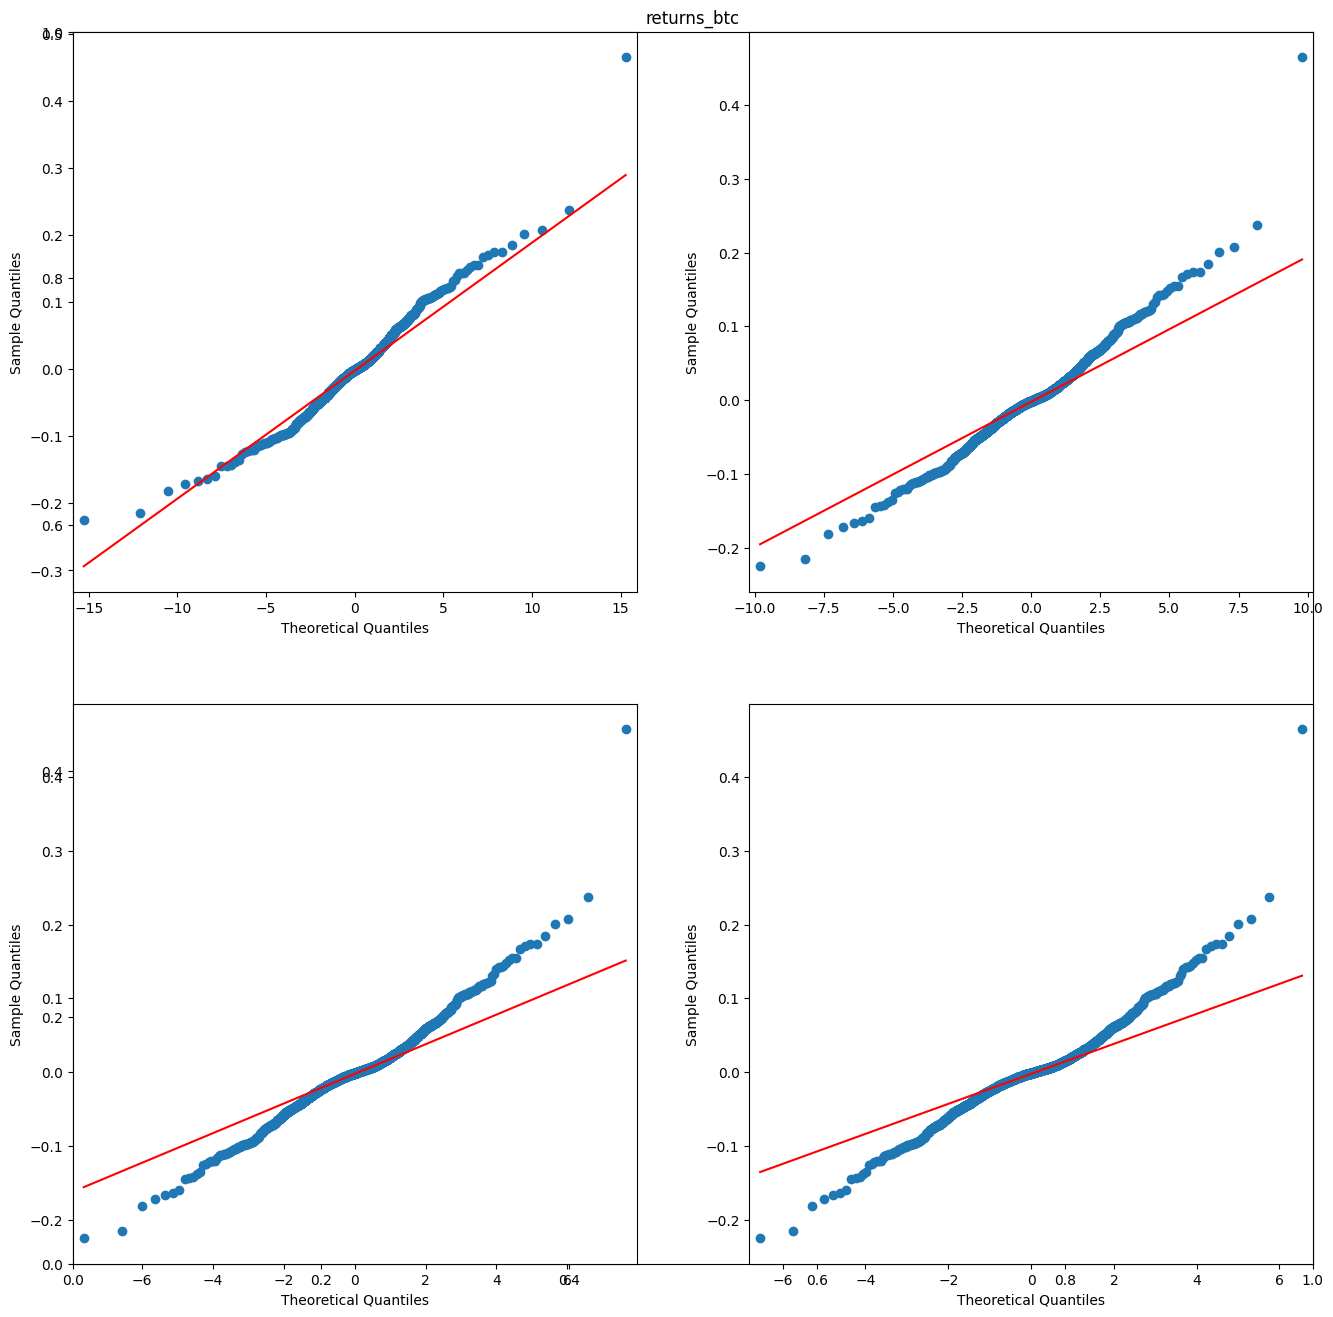

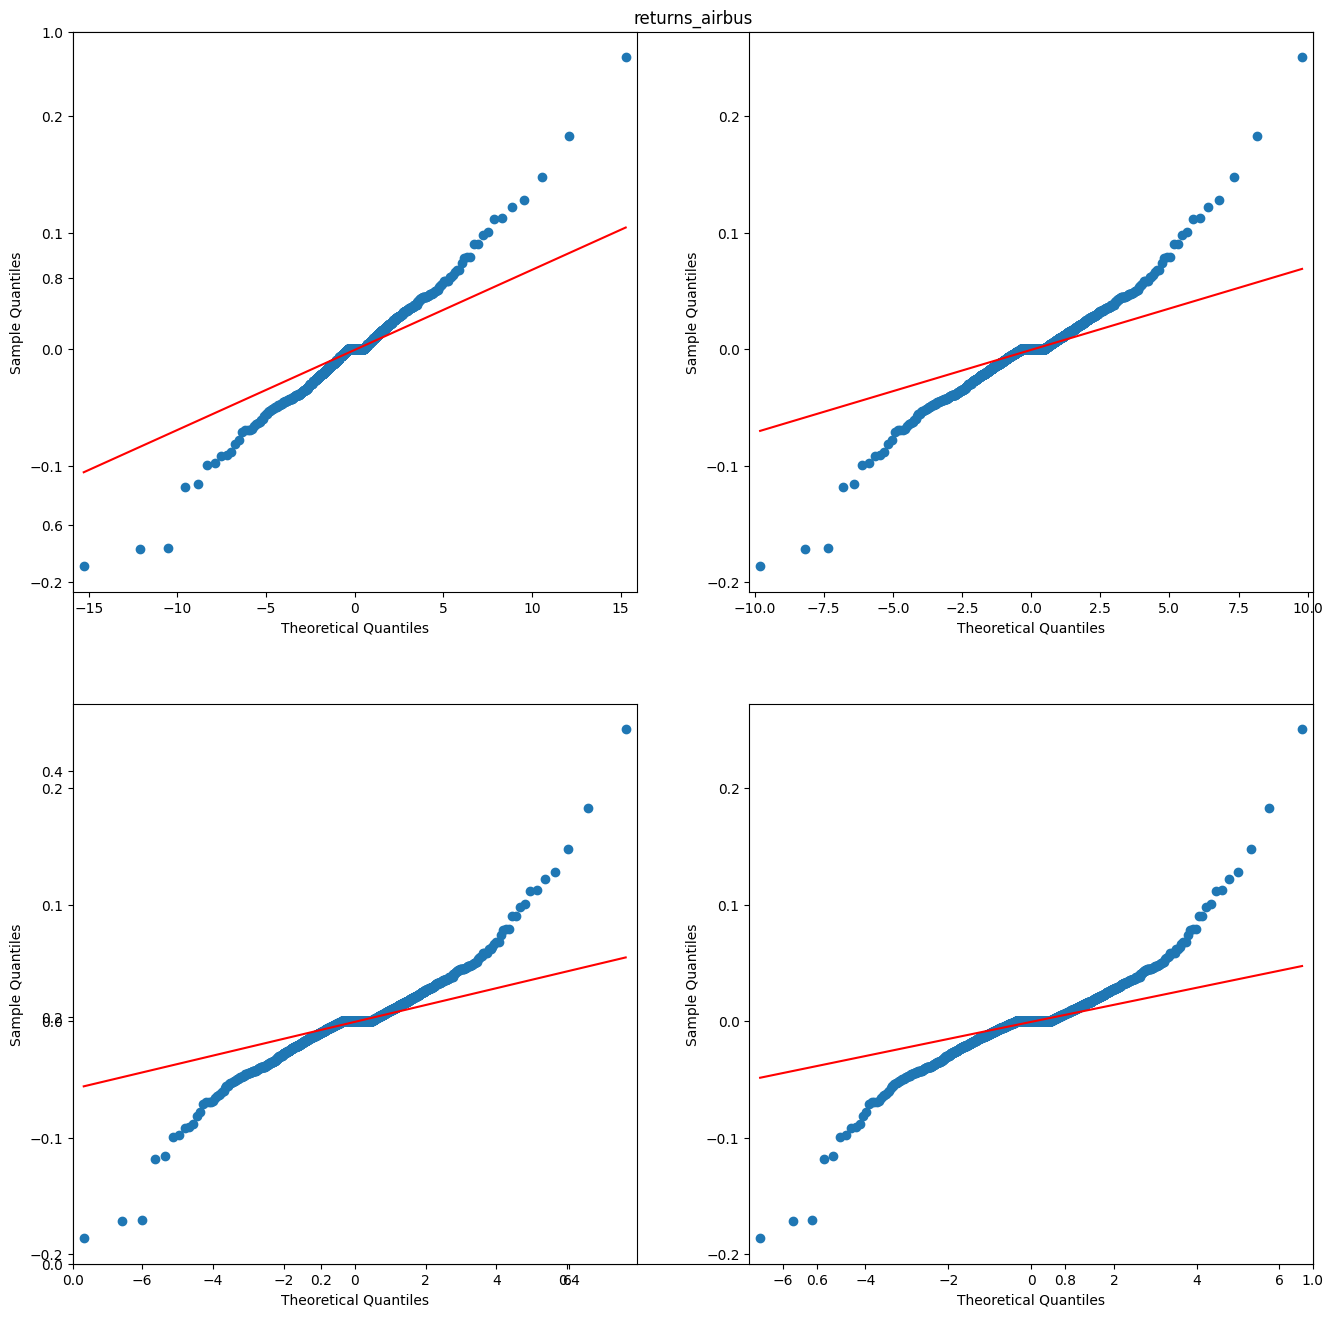

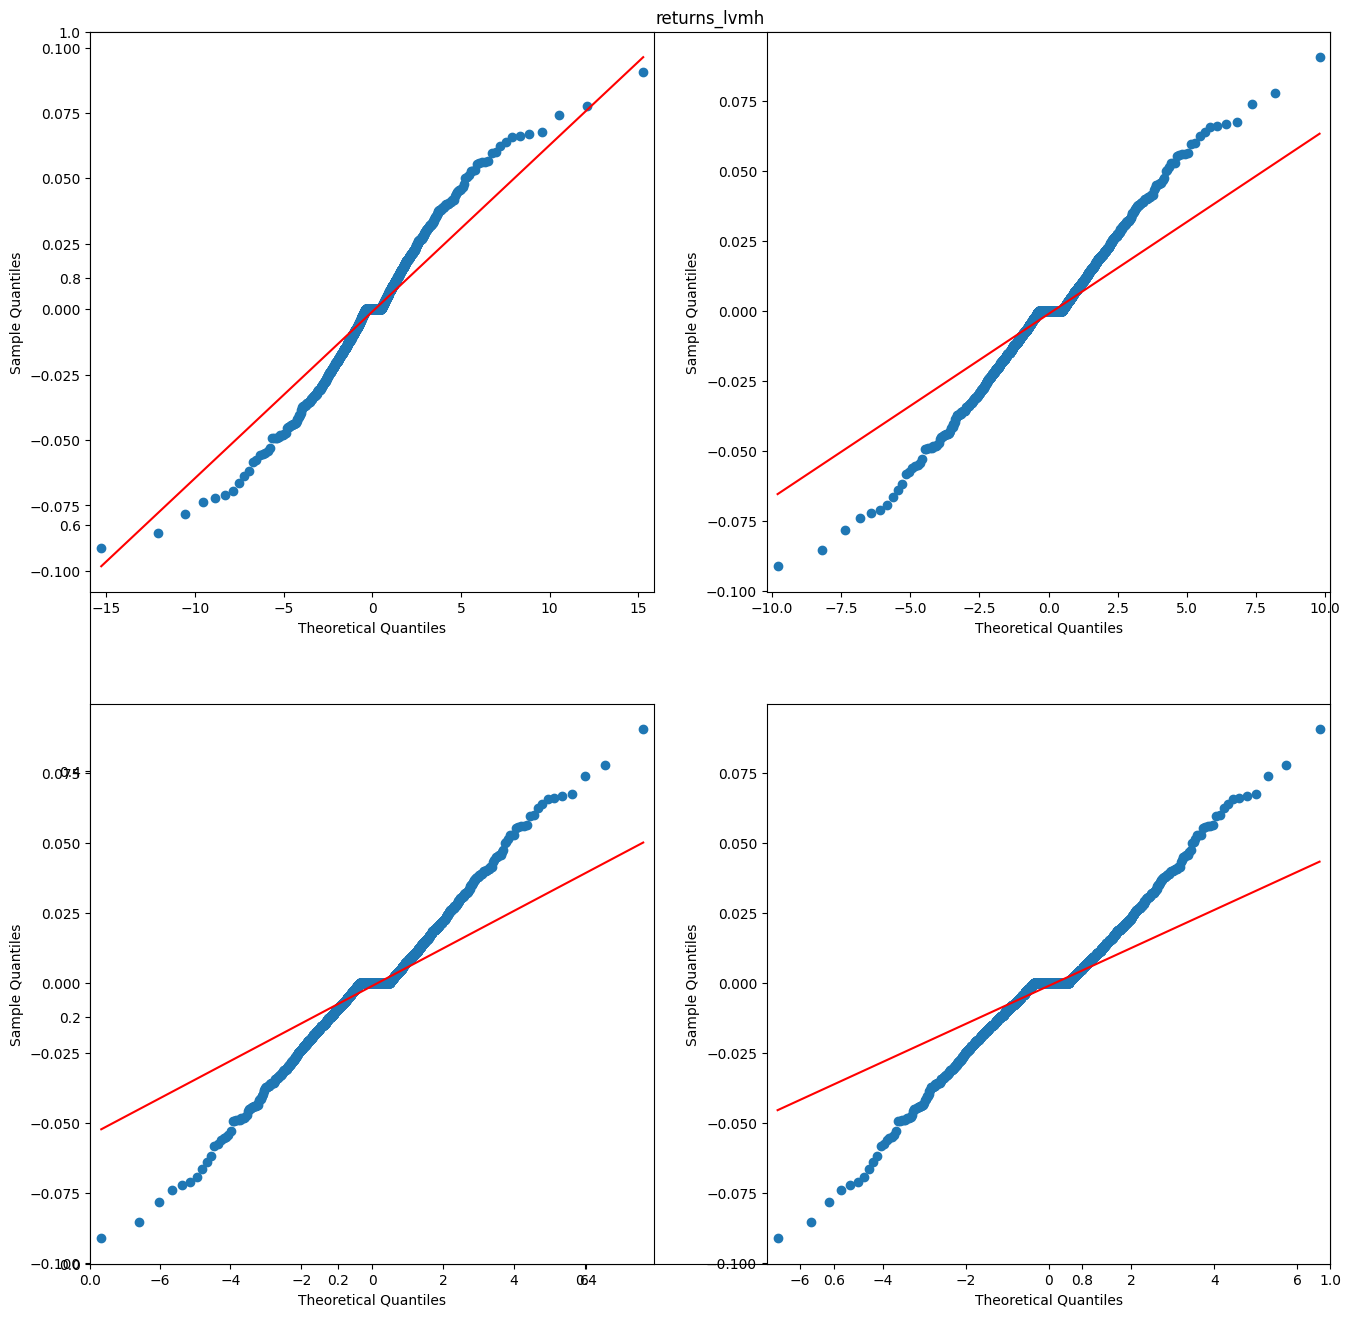

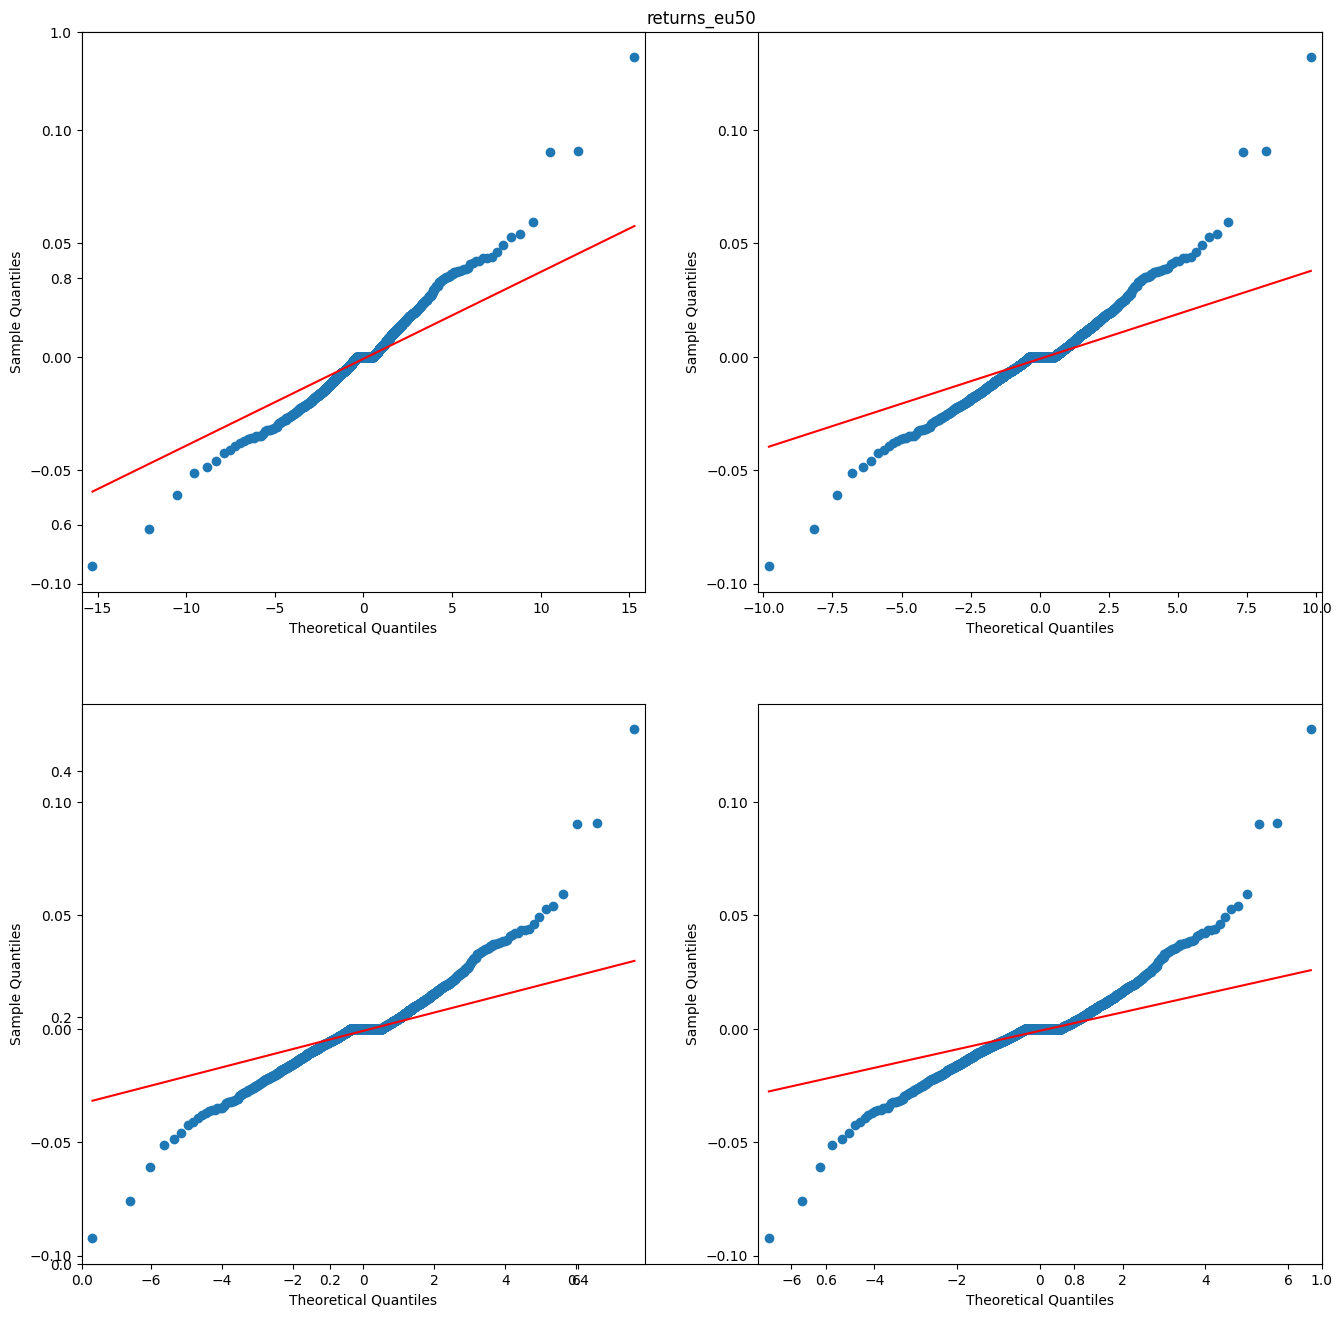

In [358]:
#QQ-plot of historical asset returns to assess validity of Student-t approximation
for i in range(N):
    j = 1
    plt.figure(figsize=(16,16))
    plt.title(portfolio_df.columns[i])
    for d in degrees_of_freedom:
        sm.qqplot(portfolio[:,i], dist=stats.t, distargs=(d,), line="q",
                  ax=plt.subplot(2,2,j))
        j += 1
    plt.show()

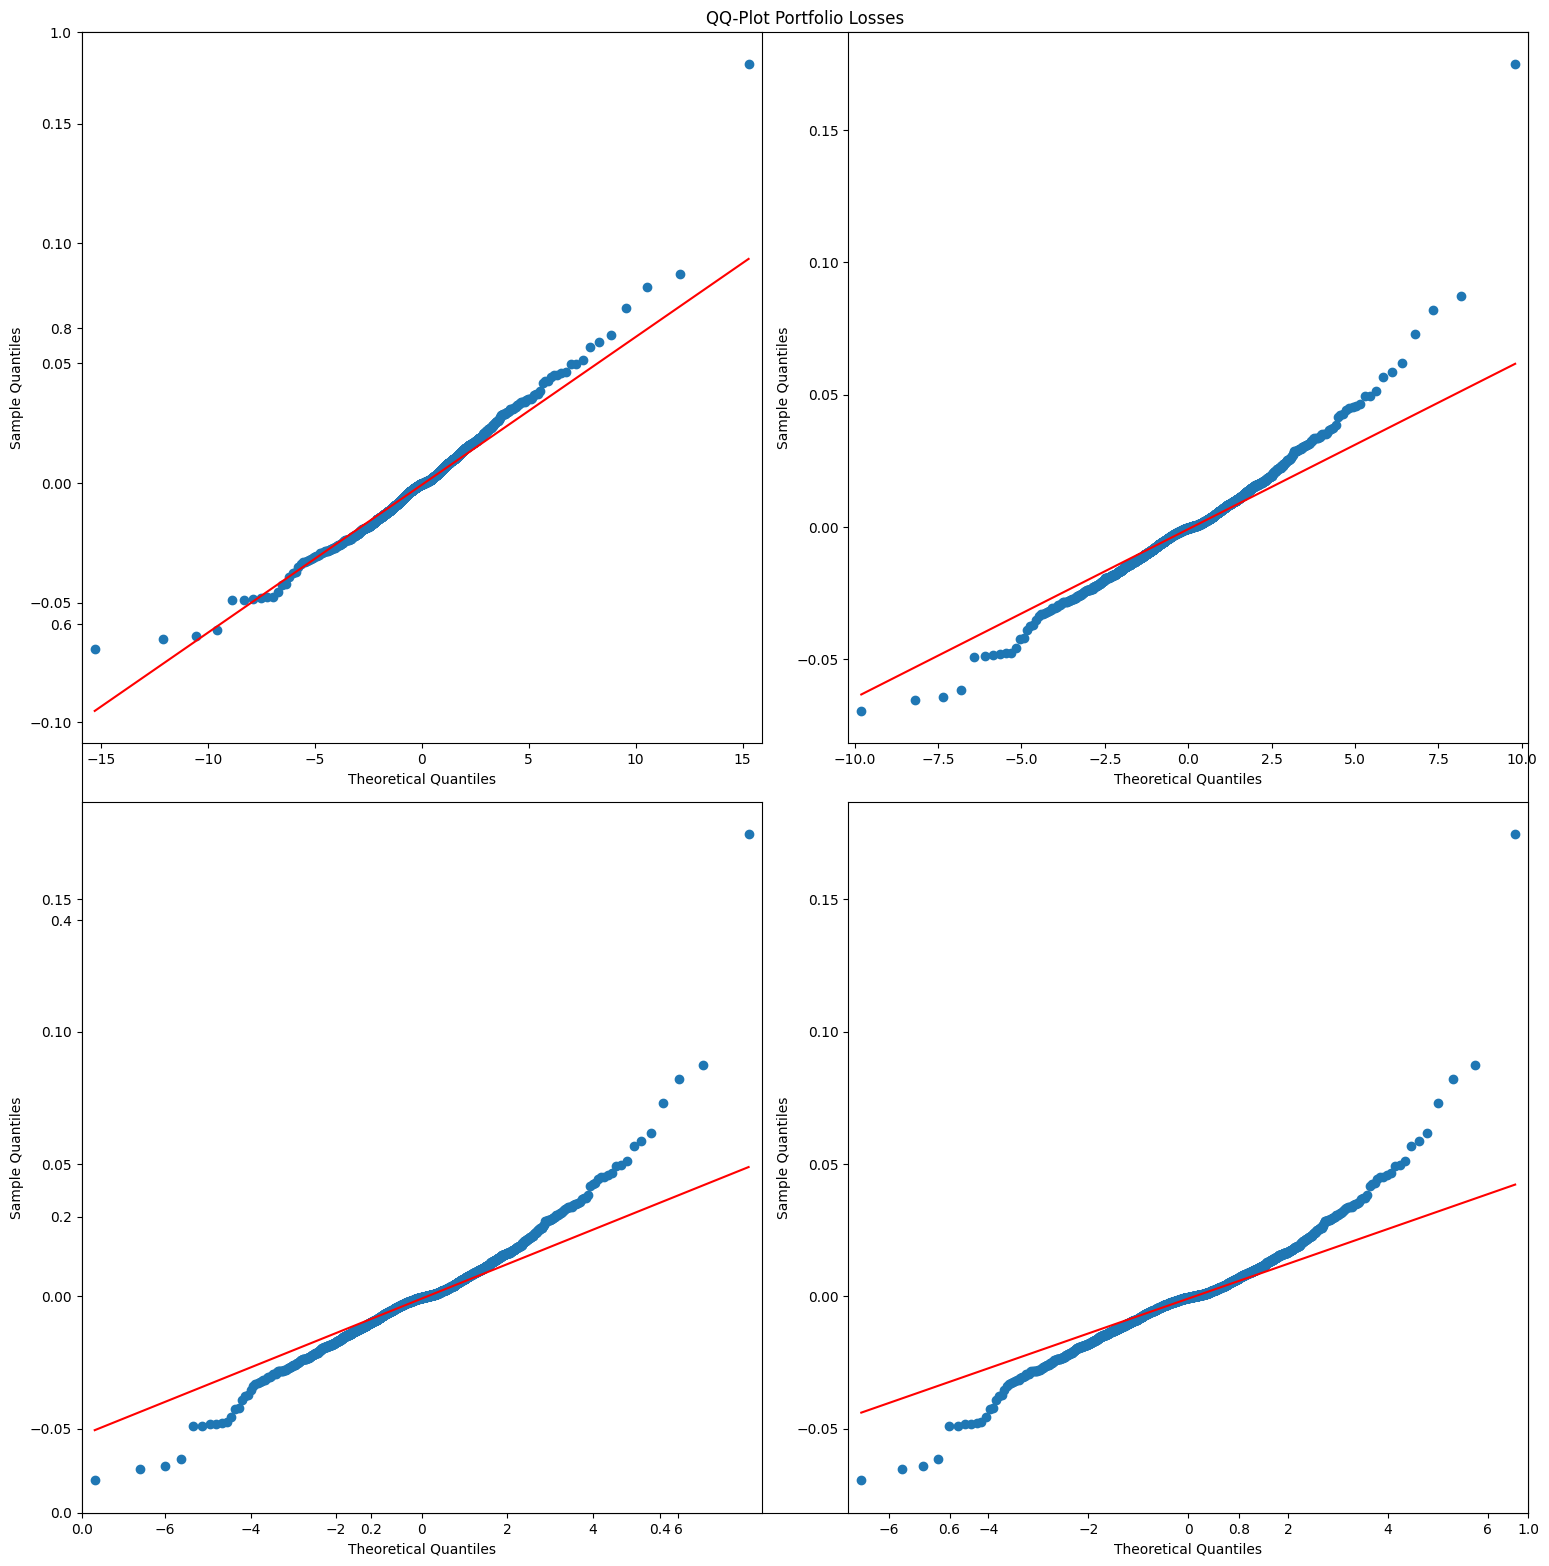

In [359]:
#QQ-plot of historical portfolio returns to assess validity of Student-t approximation
j = 1
plt.figure(figsize=(16,16))
plt.title("QQ-Plot Portfolio Losses")
for d in degrees_of_freedom:
    sm.qqplot(portfolio_weighted, dist=stats.t, distargs=(d,), line="q",
              ax=plt.subplot(2,2,j))
    plt.tight_layout()
    j += 1
plt.show()


### Conclusion: As can be seen t-Student with lowest degree fits data by far the best, because of the fattest tails

# Historical Simulation